# Where the continuous model is wrong

The checkpoint was chosen on the grouped validation split: 259 filtered RNAs, none of which shares 80% of its variable region with a training RNA. This notebook joins that split's saved predictions to the sequence, the predicted fold, and the reported measurement error.

The question is which parts of the input the model already handles, and which parts still dominate the error. Positions past the scored prefix are unlabeled and are left out. The sections above stay on that validation split. The last section scores this checkpoint and the saved RNAdegformer submission together, on the public test and on private RNAs with `test_filter == 1`.


## Load

In [1]:
import os
import tempfile
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", tempfile.mkdtemp(prefix="mpl-"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

SCORED = ["reactivity", "deg_Mg_pH10", "deg_Mg_50C"]
TARGET_LABELS = {
    "reactivity": "reactivity",
    "deg_Mg_pH10": "deg, Mg / pH 10",
    "deg_Mg_50C": "deg, Mg / 50 C",
}
TARGET_COLORS = {
    "reactivity": "#3b6d8c",
    "deg_Mg_pH10": "#d08c3a",
    "deg_Mg_50C": "#5b8f6b",
}
LOOP_ORDER = ["S", "H", "I", "B", "M", "X", "E"]
LOOP_NAMES = {
    "S": "stem",
    "H": "hairpin",
    "I": "internal loop",
    "B": "bulge",
    "M": "multiloop",
    "X": "external loop",
    "E": "dangling end",
}
ERROR_COLUMNS = {
    "reactivity": "reactivity_error",
    "deg_Mg_pH10": "deg_error_Mg_pH10",
    "deg_Mg_50C": "deg_error_Mg_50C",
}

def find_one(relatives):
    roots = [Path.cwd(), *Path.cwd().parents]
    for root in roots:
        for relative in relatives:
            path = root / relative
            if path.exists():
                return path
    raise FileNotFoundError(relatives[0])

train_path = find_one([
    "data/stanford-covid-vaccine/train.json",
    "Project/data/stanford-covid-vaccine/train.json",
])
run_dirs = sorted(path.parent for path in find_one([
    "outputs/continuous_rna",
    "Project/outputs/continuous_rna",
]).glob("*/validation_predictions.csv"))
run_dir = run_dirs[-1]
train = pd.read_json(train_path, lines=True).set_index("id")
predictions = pd.read_csv(run_dir / "validation_predictions.csv")
print("Run:", run_dir.name)
print(f"{predictions.id.nunique()} validation RNAs, {len(predictions)} stored positions")


Run: 20261113_140911_391476
259 validation RNAs, 27713 stored positions


## One row per scored nucleotide

Predictions were written for all 107 positions. Only the first 68 carry measurements. Each of those positions keeps the base, the predicted pair symbol, the bpRNA loop label, the molecule's signal-to-noise, and the experiment's reported error.


In [2]:
scored = predictions.dropna(subset=[f"true_{target}" for target in SCORED]).copy()
assert scored.position.max() == 67

pieces = []
for rna_id, part in scored.groupby("id", sort=False):
    molecule = train.loc[rna_id]
    positions = part.position.to_numpy()
    block = part.copy()
    block["base"] = [molecule.sequence[i] for i in positions]
    block["pair"] = [molecule.structure[i] for i in positions]
    block["loop"] = [molecule.predicted_loop_type[i] for i in positions]
    block["signal_to_noise"] = float(molecule.signal_to_noise)
    for target, column in ERROR_COLUMNS.items():
        errors = molecule[column]
        block[f"error_{target}"] = [float(errors[i]) for i in positions]
    pieces.append(block)
sites = pd.concat(pieces, ignore_index=True)
sites["paired"] = np.where(sites.pair.eq("."), "unpaired", "paired")
for target in SCORED:
    sites[f"residual_{target}"] = sites[f"pred_{target}"] - sites[f"true_{target}"]
    sites[f"sq_{target}"] = sites[f"residual_{target}"] ** 2

def rmse(frame, target):
    return float(np.sqrt(frame[f"sq_{target}"].mean()))

print(f"{len(sites)} scored positions")
print(sites.loop.value_counts().reindex(LOOP_ORDER).fillna(0).astype(int).to_string())


17612 scored positions
loop
S    8786
H    2082
I    1464
B     413
M     499
X     644
E    3724


## Overall error

RMSE is the square root of the mean squared error on these validation positions, the same quantity averaged across targets to make MCRMSE. The reported measurement error is the experiment's own uncertainty, averaged the same way, so a target whose RMSE sits near that floor is already close to the noise.


                   rmse  mean_abs_error  mean_residual  measurement_rmse
target                                                                  
reactivity       0.2395          0.1519         0.0023            0.1267
deg, Mg / pH 10  0.3277          0.1925         0.0001            0.1681
deg, Mg / 50 C   0.2922          0.1797         0.0023            0.1404
MCRMSE           0.2865             NaN            NaN            0.1451


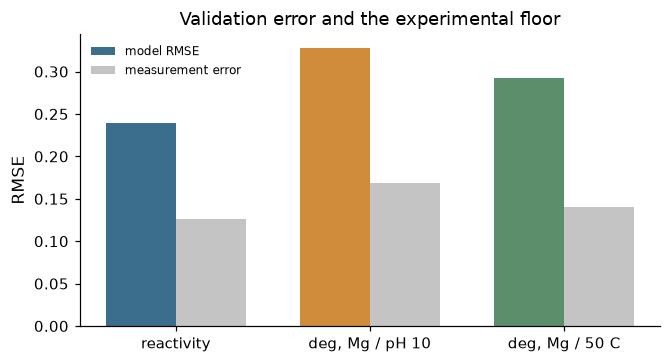

In [3]:
rows = []
for target in SCORED:
    rows.append({
        "target": TARGET_LABELS[target],
        "rmse": rmse(sites, target),
        "mean_abs_error": float(sites[f"residual_{target}"].abs().mean()),
        "mean_residual": float(sites[f"residual_{target}"].mean()),
        "measurement_rmse": float(np.sqrt((sites[f"error_{target}"] ** 2).mean())),
    })
overall = pd.DataFrame(rows).set_index("target")
overall.loc["MCRMSE"] = [overall.rmse.mean(), np.nan, np.nan, overall.measurement_rmse.mean()]
print(overall.round(4).to_string())

fig, ax = plt.subplots(figsize=(6.2, 3.4))
x = np.arange(len(SCORED))
ax.bar(x - 0.18, [rmse(sites, t) for t in SCORED], width=0.36, color=[TARGET_COLORS[t] for t in SCORED], label="model RMSE")
ax.bar(x + 0.18, [np.sqrt((sites[f"error_{t}"] ** 2).mean()) for t in SCORED], width=0.36, color="#c4c4c4", label="measurement error")
ax.set_xticks(x)
ax.set_xticklabels([TARGET_LABELS[t] for t in SCORED])
ax.set_ylabel("RMSE")
ax.set_title("Validation error and the experimental floor")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()


## Position

The constructs share a short constant prefix and the scored window stops at position 67. A model that has learned a position rule, rather than the local sequence and fold, shows up as a spike at a few indexes.


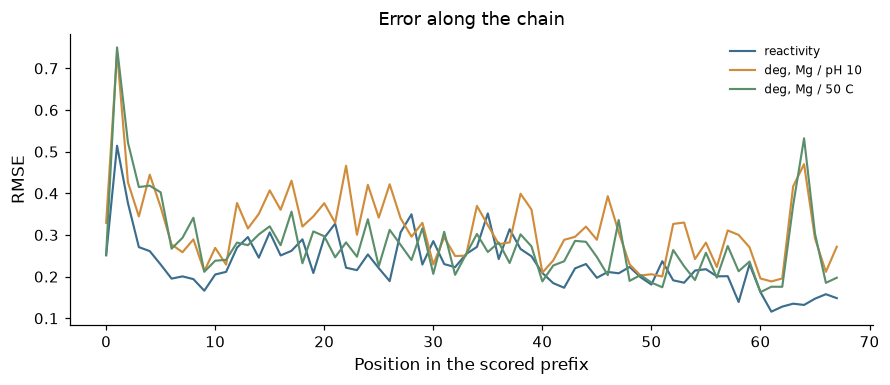

In [4]:
fig, ax = plt.subplots(figsize=(8.2, 3.6))
for target in SCORED:
    by_pos = sites.groupby("position")[f"sq_{target}"].mean().pow(0.5)
    ax.plot(by_pos.index, by_pos.to_numpy(), color=TARGET_COLORS[target], label=TARGET_LABELS[target], lw=1.4)
ax.set_xlabel("Position in the scored prefix")
ax.set_ylabel("RMSE")
ax.set_title("Error along the chain")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()


## Base, pairing, and loop type

The inputs the model actually sees are the base, the dot-bracket pair, and the loop label. Stems should be the easy case: the measurement is small and the structure is unambiguous. Hairpins and other unpaired labels are where degradation is large and the fold prediction is more often wrong.


By base
          n  reactivity  bias_reactivity  deg_Mg_pH10  bias_deg_Mg_pH10  deg_Mg_50C  bias_deg_Mg_50C
group                                                                                               
A      6342       0.255           -0.006        0.352            -0.018       0.324           -0.017
C      3451       0.140            0.004        0.236             0.010       0.223            0.020
G      4981       0.268            0.006        0.342             0.003       0.307            0.010
U      2838       0.246            0.012        0.342             0.024       0.262            0.010

By pairing
             n  reactivity  bias_reactivity  deg_Mg_pH10  bias_deg_Mg_pH10  deg_Mg_50C  bias_deg_Mg_50C
group                                                                                                  
paired    8786       0.173            0.007        0.238             0.008       0.215           -0.000
unpaired  8826       0.291           -0.002        0.398      

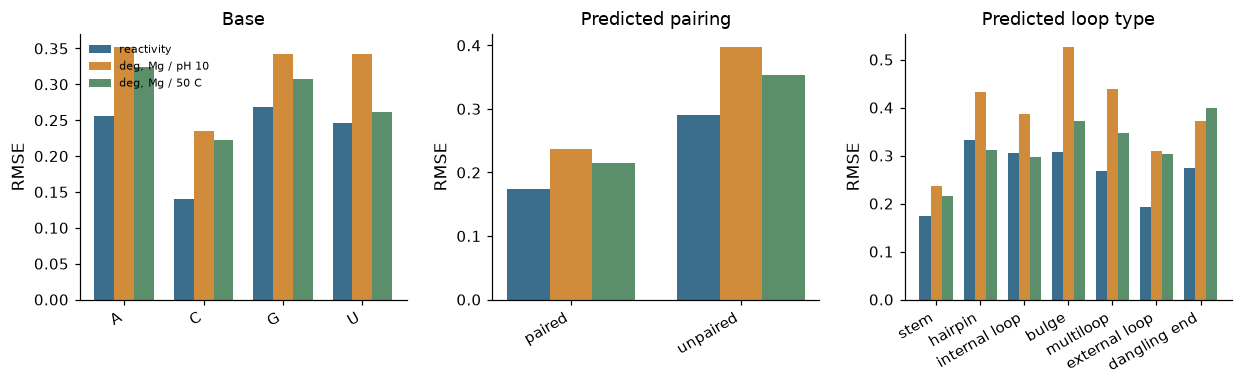

In [5]:
def rmse_by(frame, key, order):
    rows = []
    for label in order:
        part = frame.loc[frame[key].eq(label)]
        row = {"group": label, "n": len(part)}
        for target in SCORED:
            row[target] = rmse(part, target) if len(part) else np.nan
            row[f"bias_{target}"] = float(part[f"residual_{target}"].mean()) if len(part) else np.nan
        rows.append(row)
    return pd.DataFrame(rows).set_index("group")

by_base = rmse_by(sites, "base", list("ACGU"))
by_pair = rmse_by(sites, "paired", ["paired", "unpaired"])
by_loop = rmse_by(sites, "loop", LOOP_ORDER)
print("By base")
print(by_base.round(3).to_string())
print("\nBy pairing")
print(by_pair.round(3).to_string())
print("\nBy predicted loop type")
print(by_loop.rename(index=LOOP_NAMES).round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(11.4, 3.6))
panels = [
    (axes[0], by_base, list("ACGU"), list("ACGU"), "Base"),
    (axes[1], by_pair, ["paired", "unpaired"], ["paired", "unpaired"], "Predicted pairing"),
    (axes[2], by_loop, LOOP_ORDER, [LOOP_NAMES[k] for k in LOOP_ORDER], "Predicted loop type"),
]
for ax, table, order, labels, title in panels:
    x = np.arange(len(order))
    width = 0.25
    for i, target in enumerate(SCORED):
        ax.bar(x + (i - 1) * width, table.loc[order, target], width=width,
               color=TARGET_COLORS[target], label=TARGET_LABELS[target])
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_title(title)
    ax.set_ylabel("RMSE")
axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout()


## Loop type by base

A single loop label still mixes four bases. The degradation chemistry depends on both, so the grid below is RMSE for `deg, Mg / pH 10`, the target with the largest error. Empty cells are loop-base pairs that do not occur in this validation split.


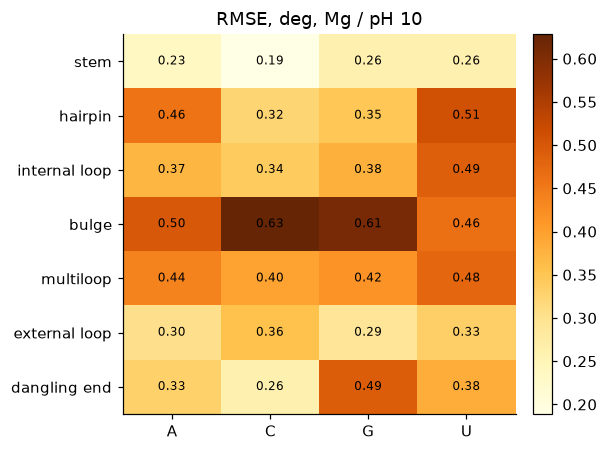

In [6]:
target = "deg_Mg_pH10"
grid = np.full((len(LOOP_ORDER), 4), np.nan)
counts = np.zeros_like(grid)
for i, loop in enumerate(LOOP_ORDER):
    for j, base in enumerate("ACGU"):
        part = sites.loc[sites["loop"].eq(loop) & sites.base.eq(base)]
        counts[i, j] = len(part)
        if len(part):
            grid[i, j] = rmse(part, target)

fig, ax = plt.subplots(figsize=(5.6, 4.2))
image = ax.imshow(grid, cmap="YlOrBr", aspect="auto")
ax.set_xticks(range(4), list("ACGU"))
ax.set_yticks(range(len(LOOP_ORDER)), [LOOP_NAMES[k] for k in LOOP_ORDER])
ax.set_title("RMSE, deg, Mg / pH 10")
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        if counts[i, j] == 0:
            continue
        ax.text(j, i, f"{grid[i, j]:.2f}", ha="center", va="center", fontsize=8, color="black")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()


## Large measurements

If the model mostly predicts the average, error grows with the measured value and the highest bins are pulled toward the middle. Each target is split into five bins with the same number of positions.


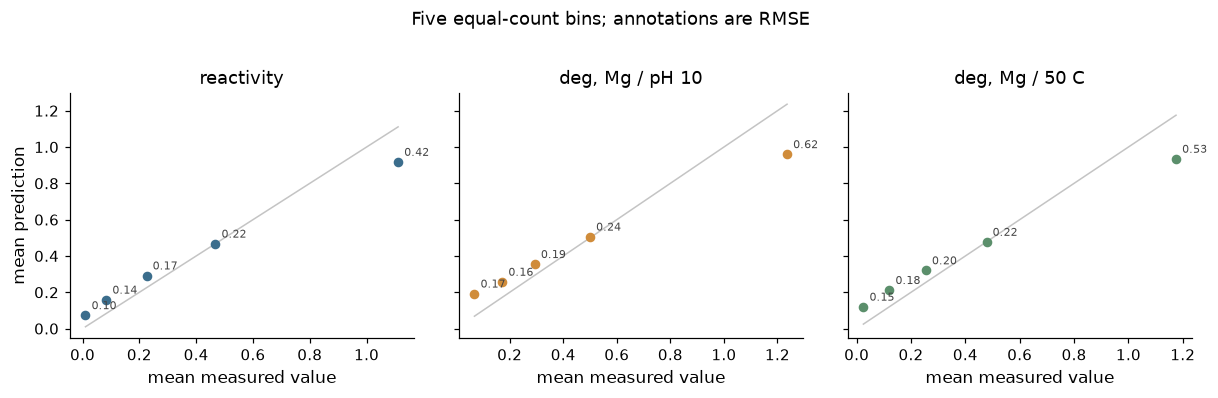

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11.2, 3.5), sharey=True)
for ax, target in zip(axes, SCORED):
    truth = sites[f"true_{target}"]
    bins = pd.qcut(truth, 5, duplicates="drop")
    part = sites.assign(bin=bins)
    summary = part.groupby("bin", observed=True).agg(
        truth=(f"true_{target}", "mean"),
        pred=(f"pred_{target}", "mean"),
        rmse=(f"sq_{target}", lambda s: np.sqrt(s.mean())),
    )
    ax.plot([summary.truth.min(), summary.truth.max()], [summary.truth.min(), summary.truth.max()],
            color="#c4c4c4", lw=1)
    ax.scatter(summary.truth, summary.pred, s=28, color=TARGET_COLORS[target], zorder=3)
    for _, row in summary.iterrows():
        ax.annotate(f"{row.rmse:.2f}", (row.truth, row.pred), textcoords="offset points",
                    xytext=(4, 4), fontsize=7, color="#444444")
    ax.set_title(TARGET_LABELS[target])
    ax.set_xlabel("mean measured value")
axes[0].set_ylabel("mean prediction")
fig.suptitle("Five equal-count bins; annotations are RMSE", y=1.02, fontsize=12)
fig.tight_layout()


## Which molecules

Signal-to-noise here is a property of the whole RNA, not of one position. A molecule RMSE that climbs as signal-to-noise falls means the remaining error is still measurement noise. A molecule with high signal-to-noise and high RMSE is a real miss.


       signal_to_noise   mcrmse  reactivity  deg_Mg_pH10  deg_Mg_50C
count          259.000  259.000     259.000      259.000     259.000
mean             5.226    0.274       0.232        0.310       0.279
std              2.397    0.069       0.061        0.105       0.088
min              1.236    0.144       0.119        0.147       0.094
25%              3.558    0.223       0.188        0.235       0.223
50%              5.169    0.263       0.224        0.289       0.259
75%              6.652    0.309       0.266        0.361       0.306
max             14.030    0.571       0.464        0.764       0.623

Lowest MCRMSE
          id  signal_to_noise  reactivity  deg_Mg_pH10  deg_Mg_50C  mcrmse
id_225d9e428            3.377       0.124        0.156       0.153   0.144
id_e27beac77            4.439       0.124        0.147       0.171   0.147
id_aff6a51a4           10.763       0.172        0.172       0.133   0.159

Highest MCRMSE
          id  signal_to_noise  reactivity  deg_M

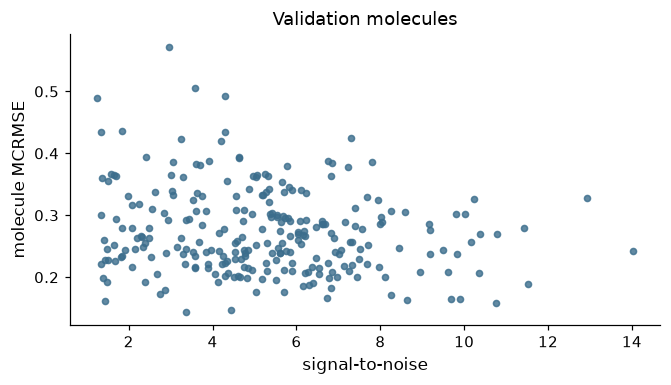

In [8]:
molecule_rows = []
for rna_id, part in sites.groupby("id"):
    row = {"id": rna_id, "signal_to_noise": float(part.signal_to_noise.iloc[0])}
    for target in SCORED:
        row[target] = rmse(part, target)
    row["mcrmse"] = float(np.mean([row[t] for t in SCORED]))
    molecule_rows.append(row)
molecules = pd.DataFrame(molecule_rows).sort_values("mcrmse")
print(molecules[["signal_to_noise", "mcrmse", *SCORED]].describe().round(3).to_string())
print("\nLowest MCRMSE")
print(molecules.head(3).round(3).to_string(index=False))
print("\nHighest MCRMSE")
print(molecules.tail(3).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.scatter(molecules.signal_to_noise, molecules.mcrmse, s=16, color="#3b6d8c", alpha=0.8)
ax.set_xlabel("signal-to-noise")
ax.set_ylabel("molecule MCRMSE")
ax.set_title("Validation molecules")
fig.tight_layout()


## A clean molecule and a miss

Both examples are drawn from the validation split by molecule MCRMSE: the median molecule, and the molecule with the largest MCRMSE. The trace is `deg, Mg / pH 10`. Pairing from the predicted structure is marked under the axis.


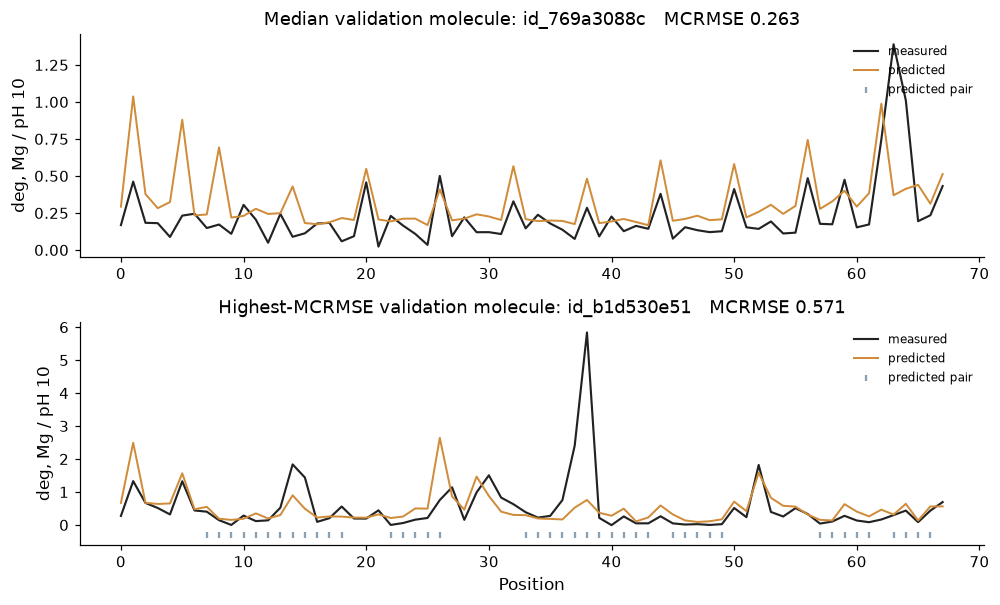

In [9]:
median_id = molecules.iloc[len(molecules) // 2].id
worst_id = molecules.iloc[-1].id

fig, axes = plt.subplots(2, 1, figsize=(9.2, 5.6), sharex=False)
for ax, rna_id, title in [
    (axes[0], median_id, "Median validation molecule"),
    (axes[1], worst_id, "Highest-MCRMSE validation molecule"),
]:
    part = sites.loc[sites.id.eq(rna_id)].sort_values("position")
    molecule = train.loc[rna_id]
    ax.plot(part.position, part.true_deg_Mg_pH10, color="#222222", lw=1.4, label="measured")
    ax.plot(part.position, part.pred_deg_Mg_pH10, color="#d08c3a", lw=1.3, label="predicted")
    paired = [i for i, char in enumerate(molecule.structure[:68]) if char != "."]
    ax.scatter(paired, np.full(len(paired), ax.get_ylim()[0]), marker="|", s=18, color="#8aa0b2", label="predicted pair")
    ax.set_title(f"{title}: {rna_id}   MCRMSE {molecules.set_index('id').loc[rna_id, 'mcrmse']:.3f}")
    ax.set_ylabel("deg, Mg / pH 10")
    ax.legend(frameon=False, fontsize=8, loc="upper right")
axes[1].set_xlabel("Position")
fig.tight_layout()


## Continuous model and RNAdegformer

RNAdegformer predictions come from `best_pl_weights_subs/submission.csv`. That file has one row per nucleotide of every public and private RNA, so it cannot be joined to the validation split above. The continuous checkpoint is the same one used in the validation sections. Both models are scored on the first `seq_scored` positions. Public RNAs are length 107, scored through 68. The private subset is length 130, scored through 91, and keeps only `test_filter == 1`.


Continuous checkpoint: 20261113_140911_391476 on mps
set
private, test_filter = 1    1172
public                       629
149,424 scored positions
                                          n  reactivity  deg_Mg_pH10  deg_Mg_50C  mcrmse
set                      model                                                          
public                   continuous     629       0.260        0.343       0.316   0.306
                         rnadegformer   629       0.211        0.260       0.231   0.234
private, test_filter = 1 continuous    1172       0.302        0.548       0.390   0.413
                         rnadegformer  1172       0.261        0.463       0.320   0.348

public: deg, Mg / pH 10 by loop
                   n  rmse_continuous  bias_continuous  rmse_rnadegformer  bias_rnadegformer
group                                                                                       
stem           22312            0.266           -0.002              0.208             -0.014
hairpi

  public                       continuous   pos1 0.800  first5 0.526  pos20-50 0.327
  public                       rnadegformer pos1 0.605  first5 0.407  pos20-50 0.248
  private, test_filter = 1     continuous   pos1 0.940  first5 0.612  pos20-50 0.569
  private, test_filter = 1     rnadegformer pos1 0.785  first5 0.506  pos20-50 0.483

Top fifth of deg, Mg / pH 10
  public: measured 1.240
    continuous   predicted 0.925  RMSE 0.643
    rnadegformer predicted 1.070  RMSE 0.490
  private, test_filter = 1: measured 1.496
    continuous   predicted 0.917  RMSE 1.110
    rnadegformer predicted 1.041  RMSE 0.947


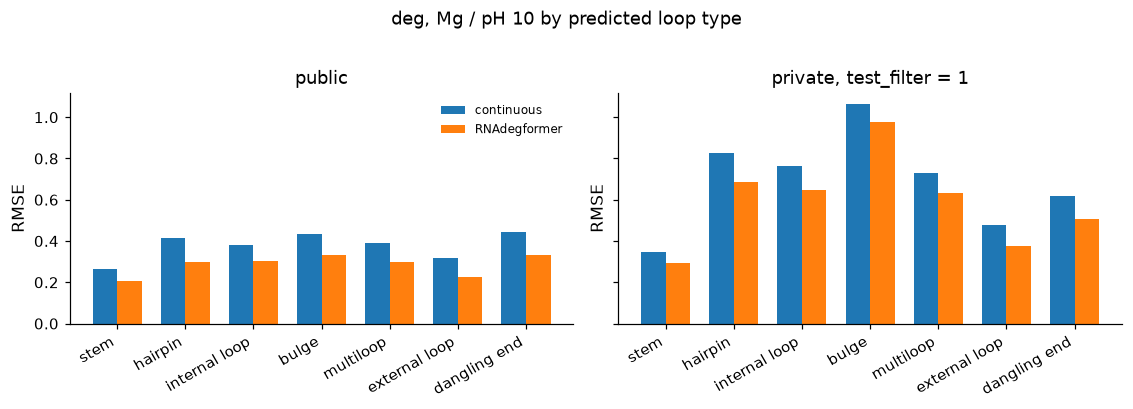

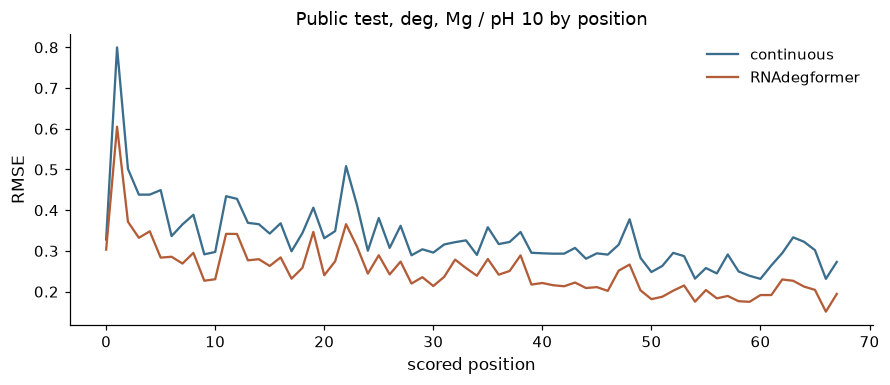

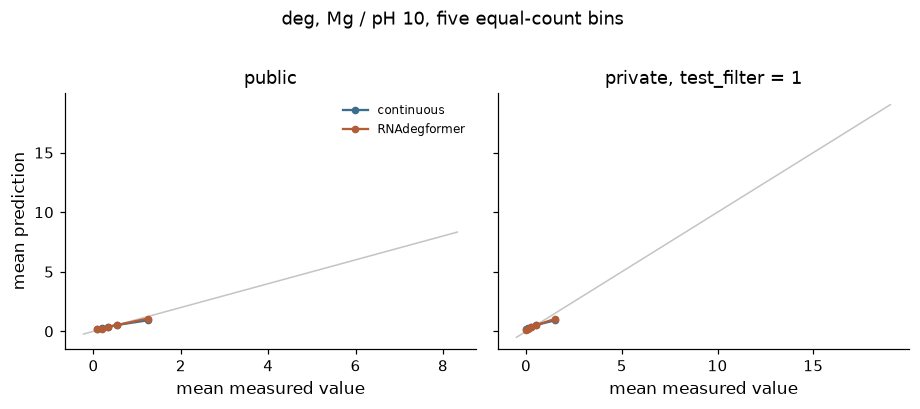

In [10]:
import math
import nbformat
import torch
from torch import nn

continuous_nb = find_one([
    "notebooks/continuous_rna.ipynb",
    "Project/notebooks/continuous_rna.ipynb",
])
source_nb = nbformat.read(continuous_nb, as_version=4)
model_src = "".join(next(
    cell.source for cell in source_nb.cells if "class ContinuousRNA" in "".join(cell.source)
))
model_src = model_src.split("model = ContinuousRNA", 1)[0]

checkpoint = torch.load(run_dir / "best_model.pt", map_location="cpu", weights_only=True)
cfg = checkpoint["config"]
VOCABS = checkpoint["vocabs"]
TARGETS = checkpoint["targets"]
BPP_FEATURE_NAMES = checkpoint["bpp_feature_names"]
device = torch.device(
    "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
)
exec(model_src, globals())
deg_model = ContinuousRNA(cfg).to(device)
deg_model.load_state_dict(checkpoint["model_state"])
deg_model.eval()

def pair_matrix(structure):
    pairs = torch.zeros(len(structure), len(structure))
    stack = []
    for i, char in enumerate(structure):
        if char == "(":
            stack.append(i)
        elif char == ")":
            j = stack.pop()
            pairs[i, j] = pairs[j, i] = 1.0
    return pairs

def load_bpp_features(bpp_dir, rna_id, length):
    probabilities = np.asarray(np.load(bpp_dir / f"{rna_id}.npy"), dtype=np.float32)
    probabilities = np.clip(probabilities, 0, 1)
    probabilities = (probabilities + probabilities.T) * 0.5
    np.fill_diagonal(probabilities, 0)
    paired = probabilities.sum(axis=1)
    probabilities /= max(1.0, float(paired.max()))
    paired = probabilities.sum(axis=1)
    unpaired = np.clip(1.0 - paired, 0.0, 1.0)
    entropy = -(probabilities * np.log(np.maximum(probabilities, 1e-12))).sum(axis=1)
    entropy -= unpaired * np.log(np.maximum(unpaired, 1e-12))
    entropy /= np.log(length + 1)
    positions = np.arange(length, dtype=np.float32)
    distance = np.abs(positions[:, None] - positions[None, :]) / max(length - 1, 1)
    expected_distance = (probabilities * distance).sum(axis=1)
    features = np.stack([
        paired, unpaired, probabilities.max(axis=1), entropy, expected_distance,
    ], axis=-1).astype(np.float32)
    return torch.from_numpy(probabilities.copy()), torch.from_numpy(features)

public_path = find_one([
    "data/public_test/public_test.json",
    "Project/data/public_test/public_test.json",
])
private_path = public_path.parent.parent / "private_test" / "private_test.json"
submission_path = find_one([
    "data/best_pl_weights_subs/submission.csv",
    "Project/data/best_pl_weights_subs/submission.csv",
])
bpp_dir = train_path.parent / "bpps"
public = pd.read_json(public_path, lines=True)
private = pd.read_json(private_path, lines=True)
private = private.loc[private.test_filter.eq(1)].reset_index(drop=True)
public["set"] = "public"
private["set"] = "private, test_filter = 1"
test_rows = pd.concat([public, private], ignore_index=True)

submission = pd.read_csv(submission_path)
split_id = submission.id_seqpos.str.rsplit("_", n=1)
submission["rna_id"] = split_id.str[0]
submission["position"] = split_id.str[1].astype(int)
former = submission.set_index(["rna_id", "position"])

class TestRNAs(torch.utils.data.Dataset):
    def __init__(self, frame):
        self.rows = frame.to_dict("records")
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, index):
        row = self.rows[index]
        length, scored = int(row["seq_length"]), int(row["seq_scored"])
        tokens = torch.tensor([
            [VOCABS[name][char] for char in row[name]] for name in VOCABS
        ], dtype=torch.long).T
        labels = torch.zeros(length, len(SCORED))
        for k, target in enumerate(SCORED):
            values = np.asarray(row[target][:scored], dtype=np.float32)
            labels[:scored, k] = torch.from_numpy(values)
        bpp, features = load_bpp_features(bpp_dir, row["id"], length)
        return dict(
            id=row["id"], set=row["set"], scored=scored, tokens=tokens,
            pairs=pair_matrix(row["structure"]), bpp=bpp, bpp_features=features,
            labels=labels, sequence=row["sequence"], structure=row["structure"],
            loop=row["predicted_loop_type"],
        )

def collate_test(items):
    batch_size = len(items)
    length = max(len(item["tokens"]) for item in items)
    batch = dict(
        tokens=torch.zeros(batch_size, length, 3, dtype=torch.long),
        pairs=torch.zeros(batch_size, length, length),
        bpp=torch.zeros(batch_size, length, length),
        bpp_features=torch.zeros(batch_size, length, len(BPP_FEATURE_NAMES)),
        valid=torch.zeros(batch_size, length, dtype=torch.bool),
    )
    meta = []
    for i, item in enumerate(items):
        n = len(item["tokens"])
        batch["tokens"][i, :n] = item["tokens"]
        batch["pairs"][i, :n, :n] = item["pairs"]
        batch["bpp"][i, :n, :n] = item["bpp"]
        batch["bpp_features"][i, :n] = item["bpp_features"]
        batch["valid"][i, :n] = True
        meta.append(item)
    return batch, meta

loader = torch.utils.data.DataLoader(
    TestRNAs(test_rows), batch_size=32, shuffle=False, collate_fn=collate_test,
)
pieces = []
with torch.inference_mode():
    for batch, meta in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        pred = deg_model(
            batch["tokens"], batch["pairs"], batch["valid"], batch["bpp"], batch["bpp_features"],
        ).cpu().numpy()
        for i, item in enumerate(meta):
            scored = item["scored"]
            block = pd.DataFrame({
                "set": item["set"],
                "id": item["id"],
                "position": np.arange(scored),
                "base": list(item["sequence"][:scored]),
                "pair": list(item["structure"][:scored]),
                "loop": list(item["loop"][:scored]),
            })
            for k, target in enumerate(SCORED):
                block[f"true_{target}"] = item["labels"][:scored, k].numpy()
                block[f"continuous_{target}"] = pred[i, :scored, k]
            pieces.append(block)
compare = pd.concat(pieces, ignore_index=True)
former_cols = submission.loc[
    submission.rna_id.isin(set(compare.id)), ["rna_id", "position", *SCORED]
].rename(columns={"rna_id": "id", **{target: f"rnadegformer_{target}" for target in SCORED}})
compare = compare.merge(former_cols, on=["id", "position"], how="left", validate="one_to_one")
if compare[[f"rnadegformer_{target}" for target in SCORED]].isna().any().any():
    raise ValueError("RNAdegformer submission is missing scored positions")
compare["paired"] = np.where(compare.pair.eq("."), "unpaired", "paired")
print(f"Continuous checkpoint: {run_dir.name} on {device}")
print(compare.groupby("set").id.nunique().to_string())
print(f"{len(compare):,} scored positions")

def model_rmse(frame, model, target):
    error = frame[f"{model}_{target}"] - frame[f"true_{target}"]
    return float(np.sqrt(np.mean(error ** 2)))

def model_bias(frame, model, target):
    return float((frame[f"{model}_{target}"] - frame[f"true_{target}"]).mean())

MODELS = ["continuous", "rnadegformer"]
MODEL_LABELS = {"continuous": "continuous", "rnadegformer": "RNAdegformer"}
summary_rows = []
for set_name, part in compare.groupby("set", sort=False):
    for model_name in MODELS:
        row = {"set": set_name, "model": model_name, "n": part.id.nunique()}
        for target in SCORED:
            row[target] = model_rmse(part, model_name, target)
        row["mcrmse"] = float(np.mean([row[target] for target in SCORED]))
        summary_rows.append(row)
summary = pd.DataFrame(summary_rows).set_index(["set", "model"])
print(summary.round(3).to_string())

def rmse_group(frame, model, key, order, target="deg_Mg_pH10"):
    rows = []
    for label in order:
        part = frame.loc[frame[key].eq(label)]
        rows.append({
            "group": label, "n": len(part),
            "rmse": model_rmse(part, model, target) if len(part) else np.nan,
            "bias": model_bias(part, model, target) if len(part) else np.nan,
        })
    return pd.DataFrame(rows).set_index("group")

for set_name, part in compare.groupby("set", sort=False):
    print(f"\n{set_name}: deg, Mg / pH 10 by loop")
    tables = {name: rmse_group(part, name, "loop", LOOP_ORDER) for name in MODELS}
    side = tables["continuous"][["n", "rmse", "bias"]].join(
        tables["rnadegformer"][["rmse", "bias"]], lsuffix="_continuous", rsuffix="_rnadegformer",
    )
    print(side.rename(index=LOOP_NAMES).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.6), sharey=True)
for ax, (set_name, part) in zip(axes, compare.groupby("set", sort=False)):
    x = np.arange(len(LOOP_ORDER))
    width = 0.36
    for i, model_name in enumerate(MODELS):
        table = rmse_group(part, model_name, "loop", LOOP_ORDER)
        ax.bar(x + (i - 0.5) * width, table.loc[LOOP_ORDER, "rmse"], width=width, label=MODEL_LABELS[model_name])
    ax.set_xticks(x)
    ax.set_xticklabels([LOOP_NAMES[k] for k in LOOP_ORDER], rotation=30, ha="right")
    ax.set_title(set_name)
    ax.set_ylabel("RMSE")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("deg, Mg / pH 10 by predicted loop type", y=1.02, fontsize=12)
fig.tight_layout()

def position_rmse(frame, model, target, start, end):
    part = frame.loc[frame.position.between(start, end - 1)]
    return model_rmse(part, model, target)

print("\nPosition slices, deg, Mg / pH 10")
for set_name, part in compare.groupby("set", sort=False):
    scored_end = int(part.position.max()) + 1
    for model_name in MODELS:
        pos1 = position_rmse(part, model_name, "deg_Mg_pH10", 1, 2)
        head = position_rmse(part, model_name, "deg_Mg_pH10", 0, 5)
        middle = position_rmse(part, model_name, "deg_Mg_pH10", 20, min(51, scored_end))
        print(f"  {set_name:28} {model_name:12} pos1 {pos1:.3f}  first5 {head:.3f}  pos20-50 {middle:.3f}")

print("\nTop fifth of deg, Mg / pH 10")
for set_name, part in compare.groupby("set", sort=False):
    threshold = part.true_deg_Mg_pH10.quantile(0.8)
    top = part.loc[part.true_deg_Mg_pH10.ge(threshold)]
    print(f"  {set_name}: measured {top.true_deg_Mg_pH10.mean():.3f}")
    for model_name in MODELS:
        print(f"    {model_name:12} predicted {top[f'{model_name}_deg_Mg_pH10'].mean():.3f}  "
              f"RMSE {model_rmse(top, model_name, 'deg_Mg_pH10'):.3f}")

public_sites = compare.loc[compare["set"].eq("public")]
fig, ax = plt.subplots(figsize=(8.2, 3.6))
for model_name, color in (("continuous", "#3b6d8c"), ("rnadegformer", "#b35c38")):
    by_pos = [
        model_rmse(public_sites.loc[public_sites.position.eq(i)], model_name, "deg_Mg_pH10")
        for i in range(68)
    ]
    ax.plot(np.arange(68), by_pos, lw=1.5, color=color, label=MODEL_LABELS[model_name])
ax.set_xlabel("scored position")
ax.set_ylabel("RMSE")
ax.set_title("Public test, deg, Mg / pH 10 by position")
ax.legend(frameon=False)
fig.tight_layout()

fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.6), sharey=True)
target = "deg_Mg_pH10"
for ax, (set_name, part) in zip(axes, compare.groupby("set", sort=False)):
    truth = part[f"true_{target}"]
    bins = pd.qcut(truth, 5, duplicates="drop")
    ax.plot([truth.min(), truth.max()], [truth.min(), truth.max()], color="#c4c4c4", lw=1)
    for model_name, color in (("continuous", "#3b6d8c"), ("rnadegformer", "#b35c38")):
        summary_bins = part.assign(bin=bins).groupby("bin", observed=True).apply(
            lambda g: pd.Series({
                "truth": g[f"true_{target}"].mean(),
                "pred": g[f"{model_name}_{target}"].mean(),
            }),
            include_groups=False,
        )
        ax.plot(summary_bins.truth, summary_bins.pred, marker="o", ms=4, color=color, label=MODEL_LABELS[model_name])
    ax.set_title(set_name)
    ax.set_xlabel("mean measured value")
axes[0].set_ylabel("mean prediction")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("deg, Mg / pH 10, five equal-count bins", y=1.02, fontsize=12)
fig.tight_layout()


## Loop type by base

MCRMSE is the mean of the three target RMSEs inside each cell. Public test positions and private RNAs with `test_filter == 1` are pooled. The color scale is shared, so a lighter cell is a lower error.


continuous
                   A      C      G      U
stem           0.281  0.220  0.268  0.265
hairpin        0.506  0.474  0.545  0.687
internal loop  0.472  0.443  0.538  0.579
bulge          0.497  0.677  0.544  0.857
multiloop      0.439  0.418  0.503  0.559
external loop  0.351  0.283  0.392  0.394
dangling end   0.440  0.338  0.536  0.618

RNAdegformer
                   A      C      G      U
stem           0.224  0.186  0.230  0.210
hairpin        0.401  0.391  0.444  0.575
internal loop  0.384  0.384  0.460  0.480
bulge          0.441  0.654  0.489  0.731
multiloop      0.365  0.379  0.447  0.496
external loop  0.293  0.231  0.296  0.329
dangling end   0.361  0.270  0.440  0.486


Text(0.5, 0.98, 'MCRMSE by predicted loop type and base')

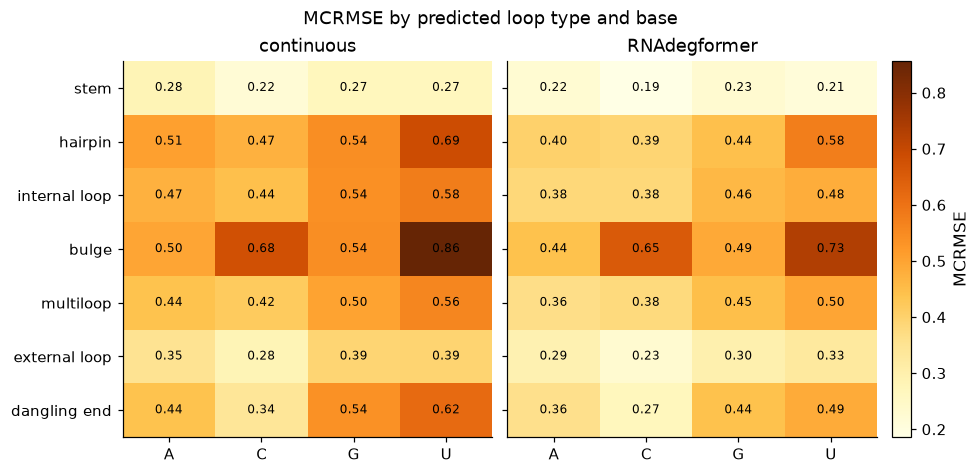

In [11]:
def cell_mcrmse(frame, model):
    if len(frame) == 0:
        return np.nan
    return float(np.mean([model_rmse(frame, model, target) for target in SCORED]))

bases = list("ACGU")
grids = {}
for model_name in MODELS:
    grid = np.full((len(LOOP_ORDER), len(bases)), np.nan)
    for i, loop in enumerate(LOOP_ORDER):
        for j, base in enumerate(bases):
            cell = compare.loc[compare["loop"].eq(loop) & compare.base.eq(base)]
            grid[i, j] = cell_mcrmse(cell, model_name)
    grids[model_name] = grid
    print(f"\n{MODEL_LABELS[model_name]}")
    print(pd.DataFrame(grid, index=[LOOP_NAMES[k] for k in LOOP_ORDER], columns=bases).round(3).to_string())

finite = np.concatenate([grid[np.isfinite(grid)] for grid in grids.values()])
vmin, vmax = float(finite.min()), float(finite.max())
fig, axes = plt.subplots(1, 2, figsize=(8.8, 4.2), sharey=True, layout="constrained")
for ax, model_name in zip(axes, MODELS):
    grid = grids[model_name]
    image = ax.imshow(grid, cmap="YlOrBr", aspect="auto", vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(bases)), bases)
    ax.set_title(MODEL_LABELS[model_name])
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            if not np.isfinite(grid[i, j]):
                continue
            ax.text(j, i, f"{grid[i, j]:.2f}", ha="center", va="center", fontsize=8, color="black")
axes[0].set_yticks(range(len(LOOP_ORDER)), [LOOP_NAMES[k] for k in LOOP_ORDER])
fig.colorbar(image, ax=axes, fraction=0.03, pad=0.02, label="MCRMSE")
fig.suptitle("MCRMSE by predicted loop type and base", fontsize=12)

## Reading

On the 259 validation RNAs the model is unbiased on average: the mean residual is about zero for all three targets. It is not yet at the measurement floor. Validation MCRMSE is 0.286, against 0.145 for the reported experimental error.

The easy regime is a predicted stem, which is the same set as the paired bases: RMSE 0.24 on `deg, Mg / pH 10`, against 0.40 when the base is unpaired. Cytosine is the easy base (0.24). Adenine, guanine, and uracil sit together near 0.34–0.35.

The misses are specific. Bulges are the worst loop label on `deg, Mg / pH 10` (RMSE 0.53, and the prediction is about 0.04 too low). Hairpins are next (0.43), also predicted slightly low. Dangling ends are the worst label for `deg, Mg / 50 C` (0.40). Multiloops are no better than hairpins on the magnesium / pH 10 target.

The 5' end is a position effect, not a smooth trend. For `deg, Mg / pH 10`, position 1 has RMSE 0.74, and the first five positions average 0.46, against 0.31 through the middle of the scored window. Those first five bases are the shared `GGAAA` cassette.

Large measurements are shrunk toward the mean. In the top fifth of `deg, Mg / pH 10` values the measured mean is 1.24 and the predicted mean is 0.96, with RMSE 0.62. The bottom fifth is pulled up, from 0.07 measured to 0.19 predicted. That shrinkage, concentrated in bulges, hairpins, and the 5' cassette, is where the remaining error sits.

Molecule signal-to-noise does not explain the worst cases. The three highest-MCRMSE RNAs have signal-to-noise between 3.0 and 4.3, while several molecules near signal-to-noise 4–11 are among the best. Those high-error RNAs are structural misses, not noisy measurements.

On the public test and on the filtered private test, RNAdegformer is ahead on every target, and the advantage is about the same size on both sets (MCRMSE 0.234 versus 0.306 on public, 0.348 versus 0.413 on private `test_filter == 1`). The shape of the error does not change. Stems stay the easy loop. On the private subset, bulges are still the worst label for `deg, Mg / pH 10` (RMSE 1.06 for the continuous model, 0.98 for RNAdegformer), and both models predict those bulges too low. Hairpins are next, with a bias of about −0.22 for both. Position 1 remains a spike on both sets: public RMSE 0.80 versus 0.61, private 0.94 versus 0.79. Large measurements are still shrunk. In the top fifth of private `deg, Mg / pH 10` values the measured mean is 1.50, against 0.92 and 1.04 predicted. RNAdegformer moves the whole curve down. It does not remove the unpaired-loop and high-value misses.
